# 02-finetune — Fine-tune backbone

**Câu hỏi**: fine-tune học gì, bằng cách nào, và đã thay đổi DINO ở đâu? (D3, D8, A5)

### Nguồn gốc (provenance)

In commit và trạng thái dirty của code, rồi đặt `XLA_FLAGS` trước mọi lần import jax (mẫu ở `lab/README.vi.md` §11).

In [1]:
# cell 0: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "lab")]
import replay; os.environ["XLA_FLAGS"] = replay._xla_flags()   # GPU deterministic mode before any jax import
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes",
                               ":(exclude)lab/*.ipynb", ":(exclude)lab/*.md")),
      "| XLA_FLAGS", os.environ["XLA_FLAGS"])

commit 69a0c2e | code dirty False | XLA_FLAGS --xla_gpu_deterministic_ops=true


- **Kết quả**: commit `69a0c2e`, code dirty False, XLA_FLAGS `--xla_gpu_deterministic_ops=true`.

## 1. Thiết lập

### 1.1 Siêu tham số và log của 6 run fine-tune

Đọc `console.log` của 6 run `ft` (GC10, NEU × r0–r2), cột tương ứng trong ngoặc:
- `FT_SEED` (FT_SEED);
- số ảnh có nhãn đem fine-tune (images);
- batch và số batch tích luỹ gradient (batch, accum);
- λ của Eq. 3, với 0 nghĩa là chỉ dùng cross-entropy, D3 (lam);
- số epoch (epochs) và số tham số học được (trainable);
- cross-entropy trung bình ở epoch đầu và epoch cuối (CE_first, CE_last).

Learning rate đọc thẳng từ `sl_finetuned_model.py`. Thêm hai thứ:
- số bước tối ưu mỗi epoch = ⌈⌈ảnh / batch⌉ / accum⌉, vì batch lẻ cuối epoch vẫn được bước một lần (flush);
- mọi dòng log nhắc tới `fbd_cuda` hoặc butterfly factor (A5).

In [2]:
# cell 1: fine-tune settings of the 6 ft runs, from the lines each run printed (console.log)
import json, math, re
import pandas as pd
src = Path("feature_extractor/sl_finetuned_model.py").read_text()
lr = re.search(r"AdamW\(lora_model\.parameters\(\), lr=([\de.-]+)\)", src)[1]
rows, warn = [], set()
for d in sorted(Path("runs").glob("*__*_ft_cls*first_img80pct_r[0-2]")):
    log = (d / "console.log").read_text(errors="replace")
    find = lambda pat: (re.search(pat, log) or [None, None])[1]
    ce = [float(x) for x in re.findall(r"Epoch \d+: mean CE = ([\d.]+)", log)]
    n, bs, acc = (int(find(p) or 0) for p in (r"fine-tune on (\d+) labeled", r"batch=(\d+)", r"accum=(\d+)"))
    warn |= {l.strip()[:160] for l in log.splitlines() if re.search(r"(?i)fbd_cuda|butterfly", l)}
    rows.append(dict(tag=d.name.split("__")[1], FT_SEED=find(r"FT_SEED=(\d+)"), images=n, batch=bs, accum=acc,
                     opt_steps_per_epoch=math.ceil(math.ceil(n / bs) / acc) if n and bs and acc else None,
                     lam=find(r"lambda=([\d.]+)"), epochs=len(ce), trainable=find(r"trainable params: ([\d,]+)"),
                     CE_first=ce[0] if ce else None, CE_last=ce[-1] if ce else None))
print("optimizer: AdamW, lr", lr, "(sl_finetuned_model.py)")
print(pd.DataFrame(rows).to_string(index=False))
print("log lines about the butterfly factor:", *sorted(warn) or ["none"], sep="\n  ")

optimizer: AdamW, lr 1e-3 (sl_finetuned_model.py)
                          tag FT_SEED  images  batch  accum  opt_steps_per_epoch lam  epochs trainable  CE_first  CE_last
gc10_ft_cls5first_img80pct_r0       0     764     32      4                    6 0.0      10   221,184    1.7700   0.1544
gc10_ft_cls5first_img80pct_r1       1     764     32      4                    6 0.0      10   221,184    1.7071   0.1514
gc10_ft_cls5first_img80pct_r2       2     764     32      4                    6 0.0      10   221,184    1.5858   0.1564
 neu_ft_cls3first_img80pct_r0       0     576     32      4                    5 0.0      10   221,184    1.0043   0.0028
 neu_ft_cls3first_img80pct_r1       1     576     32      4                    5 0.0      10   221,184    1.1163   0.0028
 neu_ft_cls3first_img80pct_r2       2     576     32      4                    5 0.0      10   221,184    1.2122   0.0037
log lines about the butterfly factor:
  /home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-pa

- **Kết quả**: AdamW, lr 1e-3. Cả 6 run có cùng thiết lập: batch 32 × accum 4 (batch hiệu dụng 128), λ = 0.0, 10 epoch, 221,184 tham số học được.
  - GC10: 764 ảnh, 6 bước tối ưu mỗi epoch. CE đi từ 1.77 / 1.71 / 1.59 (r0 / r1 / r2) xuống 0.154 / 0.151 / 0.156.
  - NEU: 576 ảnh, 5 bước mỗi epoch. CE đi từ 1.00 / 1.12 / 1.21 xuống 0.0028 / 0.0028 / 0.0037.
  - Log có cảnh báo không dựng được `fbd_cuda` (lỗi ở bước link) và dòng "Setting boft_n_butterfly_factor to 1".
- **Ý nghĩa**:
  - Fine-tune chỉ có 60 bước tối ưu với GC10 (6 × 10, tự nhân) và 50 bước với NEU.
  - CE epoch đầu gần mức đoán ngẫu nhiên: ln 5 ≈ 1.61 cho 5 lớp GC10, ln 3 ≈ 1.10 cho 3 lớp NEU. Vậy mô hình bắt đầu từ chỗ chưa biết gì về các lớp lỗi.
  - NEU gần như thuộc lòng tập huấn luyện (CE 0.003); GC10 dừng ở 0.15, chưa khớp hết sau 10 epoch.
  - λ = 0 xác nhận chỉ có cross-entropy (D3).
  - 221,184 là đúng con số của butterfly factor 1 (A5): factor 2 sẽ cho 405,504. Cả 6 run cùng con số, nên cả 6 đều chạy factor 1.
  - Các dòng cảnh báo gộp từ cả 6 log, nên bảng này không cho biết run nào in dòng nào; con số trainable mới là bằng chứng cho từng run.

### 1.2 Mô hình thật sự được fine-tune

Dựng lại mô hình bằng chính `load_model()` của `sl_finetuned_model.py` trên CPU, không huấn luyện:
- đếm tham số học được theo loại: ma trận xoay `boft_R`, hệ số co `boft_s`, bias (`bias="boft_only"`), và head;
- liệt kê các module mà BOFT bọc;
- kiểm pooler có bị đóng băng không;
- so tên và shape với checkpoint `ft_ckpt.pt` của GC10 r0.

`target_modules` ghi `output.dense`, `mlp.fc1`, `mlp.fc2`. Module nào khớp tuỳ cách thư viện `transformers` đặt tên các lớp của ViT, nên cell in kèm phiên bản thư viện.

In [3]:
# cell 2: the model that was fine-tuned: load_model() of sl_finetuned_model.py built on the CPU (no training),
#         its trainable parameters by kind, the modules BOFT wraps, and the checkpoint of GC10 ft r0 against it
import sys, collections, importlib.metadata as md
import torch
os.environ.setdefault("HF_HUB_OFFLINE", "1")                    # DINO weights from the local cache
sys.path.insert(0, str(ROOT / "feature_extractor"))
from sl_finetuned_model import load_model
print("transformers", md.version("transformers"), "| peft", md.version("peft"), "| torch", torch.__version__)
model = load_model(10, "dino_vitb16")                           # GC10: dino-neudet.py passes num_classes = len(split["classes"]) = 10
params = dict(model.named_parameters())
kind = lambda n: "head" if n.startswith("head.") else (re.search(r"(boft_R|boft_s)", n) or [None, "bias (boft_only)"])[1]
tab = collections.defaultdict(lambda: [0, 0, None])
for n, p in params.items():
    if p.requires_grad:
        t = tab[kind(n)]
        t[0], t[1], t[2] = t[0] + 1, t[1] + p.numel(), tuple(p.shape)
print(pd.DataFrame([dict(kind=k, tensors=v[0], params=v[1], shape=v[2]) for k, v in tab.items()]).to_string(index=False))
adapted = sorted({re.sub(r"\.boft_R.*", "", n) for n, p in params.items() if p.requires_grad and "boft_R" in n})
print("modules wrapped by BOFT:", len(adapted), dict(collections.Counter(re.sub(r".*layers?\.\d+\.", "", m) for m in adapted)))
print("modules named mlp.fc1 / mlp.fc2 in this model:", sum(bool(re.search(r"mlp\.fc[12]$", n)) for n, _ in model.named_modules()))
print("pooler trainable:", {n.split("model.")[-1]: p.requires_grad for n, p in params.items() if "pooler" in n})
CKPT = next(Path("features").glob("*__gc10_ft_cls5first_img80pct_r0")) / "ft_ckpt.pt"
ck = torch.load(CKPT, map_location="cpu", weights_only=True)
want = {n: tuple(p.shape) for n, p in params.items() if p.requires_grad or "pooler.dense" in n}   # what PATCH 5 saves
got = {n: tuple(t.shape) for n, t in ck["state"].items()}
print(f"{CKPT}: epoch {ck['epoch']} | tensors {len(got)} | params {sum(t.numel() for t in ck['state'].values()):,} "
      f"| names and shapes = this model: {got == want}")

/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers 4.46.3 | peft 0.13.2 | torch 2.4.0+cu121


Some weights of ViTModel were not initialized from the model checkpoint at facebook/dino-vitb16 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Using /home/rito/.cache/torch_extensions/py312_cu121 as PyTorch extensions root...
Detected CUDA files, patching ldflags
Emitting ninja build file /home/rito/.cache/torch_extensions/py312_cu121/fbd_cuda/build.ninja...
/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/torch/utils/cpp_extension.py:1965: UserWarning: TORCH_CUDA_ARCH_LIST is not set, all archs for visible cards are included for compilation. 
If this is not desired, please set os.environ['TORCH_CUDA_ARCH_LIST'].
  warnings.warn(
Building extension module fbd_cuda...
Allowing ninja to set a default number of workers... (overridable by setting the environment variable MAX_JOBS=N)


[1/1] gcc fbd_cuda.o fbd_cuda_kernel.cuda.o -shared -L/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/torch/lib -lc10 -lc10_cuda -ltorch_cpu -ltorch_cuda -ltorch -ltorch_python -L/home/rito/miniforge3/envs/vbcgcd/lib -lcudart -o fbd_cuda.so
FAILED: [code=1] fbd_cuda.so 
gcc fbd_cuda.o fbd_cuda_kernel.cuda.o -shared -L/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/torch/lib -lc10 -lc10_cuda -ltorch_cpu -ltorch_cuda -ltorch -ltorch_python -L/home/rito/miniforge3/envs/vbcgcd/lib -lcudart -o fbd_cuda.so
/usr/bin/ld: cannot find -lcudart: No such file or directory
collect2: error: ld returned 1 exit status
ninja: build stopped: subcommand failed.


/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/peft/tuners/boft/layer.py:95: UserWarning: Failed to load the CUDA extension: Error building extension 'fbd_cuda', check if ninja is available.
  warnings.warn(f"Failed to load the CUDA extension: {e}, check if ninja is available.")
/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/peft/tuners/boft/layer.py:96: UserWarning: Setting boft_n_butterfly_factor to 1 to speed up the finetuning process.
  warnings.warn("Setting boft_n_butterfly_factor to 1 to speed up the finetuning process.")
Using /home/rito/.cache/torch_extensions/py312_cu121 as PyTorch extensions root...
No modifications detected for re-loaded extension module fbd_cuda, skipping build step...
Loading extension module fbd_cuda...
/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/peft/tuners/boft/layer.py:95: UserWarning: Failed to load the CUDA extension: /home/rito/.cache/torch_extensions/py312_cu121/fbd_cuda/fbd_cuda.so: cannot open s

trainable params: 221,184 || all params: 86,592,000 || trainable%: 0.2554
            kind  tensors  params          shape
bias (boft_only)       24   18432         (768,)
          boft_R       24  184320 (1, 768, 4, 4)
          boft_s       24   18432       (768, 1)
            head        2    7690          (10,)
modules wrapped by BOFT: 24 {'attention.output.dense': 12, 'output.dense': 12}
modules named mlp.fc1 / mlp.fc2 in this model: 0
pooler trainable: {'pooler.dense.weight': False, 'pooler.dense.bias': False}
features/20261005_013115__gc10_ft_cls5first_img80pct_r0/ft_ckpt.pt: epoch 9 | tensors 76 | params 819,466 | names and shapes = this model: True


- **Kết quả**: transformers 4.46.3, peft 0.13.2, torch 2.4.0+cu121. peft lại thử dựng `fbd_cuda` và lỗi ở bước link (`cannot find -lcudart`), như lúc fine-tune. Tham số học được của backbone là 221,184 trên tổng 86,592,000 (0.2554%):
  - `boft_R`: 24 tensor, 184,320 tham số, shape `(1, D, 4, 4)`; số 1 đầu tiên là butterfly factor;
  - `boft_s`: 24 tensor, 18,432 tham số;
  - bias (`boft_only`): 24 tensor, 18,432 tham số;
  - head ngoài backbone: 2 tensor, 7,690 tham số (Linear 768 → 10).

  BOFT bọc 24 module: 12 `attention.output.dense` và 12 `output.dense` (lớp thứ hai của MLP). Không module nào tên `mlp.fc1` hay `mlp.fc2`. Pooler không học. Checkpoint r0 lưu ở epoch 9: 76 tensor, 819,466 tham số, tên và shape trùng mô hình.
- **Ý nghĩa**: xác nhận A5 ngay trên mô hình, không cần suy từ số đếm.
  - Factor 1 có trong chính shape của `boft_R`.
  - `mlp.fc1` và `mlp.fc2` (tên của timm) không khớp gì, nên `intermediate.dense` (lớp thứ nhất của MLP), query, key, value đều giữ nguyên trọng số đã học sẵn.
  - Tự cộng: 819,466 = 221,184 (BOFT) + 7,690 (head) + 590,592 (pooler 768 × 768 + 768). Ứng với PATCH 5 cho GC10; con số 888,676 ở `check_phase1.py` là cho head 100 lớp của CIFAR.
  - [SUY LUẬN] Module nào được fine-tune phụ thuộc cách `transformers` đặt tên lớp. Chạy thử với `transformers` 5.22, các lớp đổi tên thành `mlp.fc1`/`mlp.fc2` nên cùng cấu hình lại bọc 24 module MLP (276,480 tham số). Nâng phiên bản thư viện sẽ âm thầm đổi lớp được fine-tune; con số trainable trong log là cách phát hiện.
  - Head có 10 lối ra nhưng chỉ 5 lớp có ảnh; 5 lối ra của lớp mới không bao giờ là đích của cross-entropy.

## 2. Toán của BOFT

### 2.1 Một module, tính tay

Orthogonal fine-tuning (OFT; Qiu et al. 2023) giữ nguyên ma trận trọng số đã học sẵn W và chỉ học một phép xoay R (ma trận trực giao, RᵀR = I) áp lên nó. Phép xoay giữ nguyên góc giữa các nơ-ron, tức giữ "năng lượng siêu cầu" (hyperspherical energy) của W; các tác giả cho rằng đó là phần chứa tri thức đã học sẵn. BOFT (Liu et al., ICLR 2024) ghép R từ m nhân tử bướm (butterfly factor), mỗi nhân tử là một ma trận khối chéo gồm các khối b × b, kẹp giữa các hoán vị P. Ở đây m = 1 và b = 4 (1.2), nên R chỉ là P·B·Pᵀ, với B gồm các khối 4 × 4 nằm trên đường chéo.

**Cách làm**:
1. Mỗi khối học 16 số tự do A. Lấy phần phản đối xứng S = (A − Aᵀ) / 2, rồi qua biến đổi Cayley Q = (I − S)(I + S)⁻¹, ta được Q trực giao với mọi A.
   Chứng minh: (I − S) và (I + S) giao hoán, và Sᵀ = −S, nên QᵀQ = (I − S)⁻¹(I + S)(I − S)(I + S)⁻¹ = I.
   Khởi tạo: A = 0 cho Q = I và s = 1, nên fine-tune bắt đầu đúng từ DINO gốc.
2. Trọng số hiệu dụng (effective weight): W′ = diag(s) · W · Mᵀ, với M = P·B·Pᵀ. Phép xoay tác động lên chiều vào (input) của lớp tuyến tính; mỗi nơ-ra có thêm hệ số co s, và bias được học (`boft_only`).

Cell nạp checkpoint r0 vào mô hình, lấy module đầu tiên (lớp 0, `attention.output.dense`), dựng lại Q, B, M theo công thức trên bằng code riêng, rồi kiểm ba điều:
- Q và M có trực giao không;
- góc xoay của các khối, đọc từ trị riêng e^{±iθ} của Q;
- lối ra tính tay có trùng lối ra của peft trên 5 vector ngẫu nhiên không.

In [4]:
# cell 3: BOFT on one module, by hand: the checkpoint of GC10 ft r0 loaded into the model; the effective weight
#         W' = diag(s) W M^T with M = P B P^T, B = block-diag of Cayley blocks, rebuilt here and checked against peft's forward
torch.set_printoptions(precision=4, sci_mode=False)
miss, extra = model.load_state_dict(ck["state"], strict=False)  # missing = the frozen pretrained weights, kept as loaded
assert not extra and all(not params[n].requires_grad and "pooler.dense" not in n for n in miss)
model.eval()                                                    # boft_dropout off, as at extraction (model.eval() in extract)
name = adapted[0]                                               # first wrapped module: layer 0, attention.output.dense
mod = model.get_submodule(name)
A = mod.boft_R["default"].detach()[0]                           # D x 4 x 4 free parameters (butterfly factor 1)
S = 0.5 * (A - A.transpose(1, 2))                               # skew-symmetric part: S^T = -S
I4 = torch.eye(4).expand_as(S)
Q = (I4 - S) @ torch.linalg.inv(I4 + S)                         # Cayley transform: orthogonal, det = +1
B = torch.block_diag(*Q)                                        # in_features x in_features
P = mod.boft_P.detach()[0].to(B)
M = P @ B @ P.T
W, b, s = mod.base_layer.weight.detach(), mod.base_layer.bias.detach(), mod.boft_s["default"].detach()[:, 0]
x = torch.randn(5, W.shape[1])
with torch.no_grad():
    y_peft, y_hand = mod(x), (x @ M) @ W.T * s + b
ang = torch.angle(torch.linalg.eigvals(Q)).abs().amax(1) * 180 / torch.pi   # rotation angle of each 4x4 block, degrees
print(f"module {name.split('model.')[-1]} | W {tuple(W.shape)} | {Q.shape[0]} blocks of 4x4 | P is identity: {bool((P == torch.eye(len(P))).all())}")
print("block 0: free parameters A[0] =", A[0], "skew part S[0] =", S[0], "Cayley Q[0] = (I - S)(I + S)^-1 =", Q[0], sep="\n")
print(f"max |Q^T Q - I| over blocks {(Q.transpose(1, 2) @ Q - I4).abs().max():.1e} | max |M^T M - I| {(M.T @ M - torch.eye(len(M))).abs().max():.1e}")
print(f"rotation angle per block (deg): median {ang.median():.3f}, max {ang.max():.3f} | |Q - I|_F median {(Q - I4).flatten(1).norm(dim=1).median():.4f}")
print(f"scale s: min {s.min():.4f}, median {s.median():.4f}, max {s.max():.4f} | max |y_peft - y_hand| {(y_peft - y_hand).abs().max():.1e} "
      f"(max |y| {y_peft.abs().max():.2f})")

module encoder.layer.0.attention.output.dense | W (768, 768) | 192 blocks of 4x4 | P is identity: True
block 0: free parameters A[0] =
tensor([[ 0.0000,  0.0066, -0.0224, -0.0212],
        [-0.0066,  0.0000, -0.0178, -0.0007],
        [ 0.0224,  0.0178,  0.0000, -0.0232],
        [ 0.0212,  0.0007,  0.0232,  0.0000]])
skew part S[0] =
tensor([[ 0.0000,  0.0066, -0.0224, -0.0212],
        [-0.0066,  0.0000, -0.0178, -0.0007],
        [ 0.0224,  0.0178,  0.0000, -0.0232],
        [ 0.0212,  0.0007,  0.0232,  0.0000]])
Cayley Q[0] = (I - S)(I + S)^-1 =
tensor([[     0.9980,     -0.0141,      0.0434,      0.0433],
        [     0.0124,      0.9993,      0.0358,      0.0026],
        [    -0.0459,     -0.0353,      0.9973,      0.0453],
        [    -0.0412,     -0.0003,     -0.0473,      0.9980]])
max |Q^T Q - I| over blocks 3.6e-07 | max |M^T M - I| 3.6e-07
rotation angle per block (deg): median 4.327, max 7.968 | |Q - I|_F median 0.1098
scale s: min 0.9577, median 0.9970, max 1.0497 | ma

- **Kết quả**: module `encoder.layer.0.attention.output.dense`, W 768 × 768, 192 khối 4 × 4, P là ma trận đơn vị.
  - A[0] học được đã phản đối xứng sẵn, nên S[0] = A[0]. Ví dụ phần tử (0, 2): A = −0.0224, phần tử (2, 0): A = 0.0224.
  - Q[0] gần I: đường chéo 0.997–0.999, ngoài đường chéo tới 0.047.
  - Q và M trực giao tới 3.6e-07.
  - Góc xoay mỗi khối: trung vị 4.327°, lớn nhất 7.968°; ‖Q − I‖_F trung vị 0.1098.
  - Hệ số co s: 0.9577 đến 1.0497 (trung vị 0.9970).
  - Lối ra tính tay lệch lối ra của peft tối đa 9.5e-07, trong khi |y| lớn nhất là 11.12.
- **Ý nghĩa**:
  - Công thức W′ = diag(s) · W · Mᵀ, M = P·B·Pᵀ, Q = (I − S)(I + S)⁻¹ mô tả đúng cách peft 0.13.2 tính; lệch còn lại là sai số float32.
  - A tự nằm trên tập ma trận phản đối xứng. [SUY LUẬN] Lý do: A khởi tạo bằng 0, gradient chỉ đi qua phần S nên cũng phản đối xứng, và weight decay của AdamW chỉ co A theo tỉ lệ, nên A không rời tập đó.
  - Fine-tune chỉ xoay nhẹ: mỗi khối 4 kênh vào xoay vài độ, và mỗi nơ-ra co giãn trong khoảng ±5%.
  - [SUY LUẬN] Vì P = I và factor 1, chỉ 4 kênh liền nhau trộn được với nhau. Fine-tune không thể trộn hai kênh xa nhau, nên khả năng thay đổi biểu diễn rất hẹp. Factor 2 (bản paper có thể đã dùng, A5) sẽ trộn xa hơn.

### 2.2 Fine-tune thay đổi lớp nào

Đo trên từng module trong 24 module được bọc, với cả ba checkpoint GC10 (r0–r2):
- thay đổi tương đối của trọng số hiệu dụng ‖W′ − W‖_F / ‖W‖_F, với W′ = diag(s) · W · Mᵀ như 2.1 (gộp cả phép xoay lẫn hệ số co);
- góc xoay trung vị của các khối 4 × 4;
- thay đổi tương đối của bias so với bias của DINO gốc.

Câu hỏi: fine-tune dồn vào lớp sâu (gần lối ra) hay lớp nông, vào nhánh attention hay MLP, và ba FT seed có giống nhau không.

In [5]:
# cell 4: where fine-tuning changed DINO: for each wrapped module and each GC10 checkpoint (r0-r2), the relative change
#         of the effective weight |W' - W|_F / |W|_F, the median rotation angle of its 4x4 blocks, and the bias change
from transformers import AutoModel
base_bias = {n: p.detach() for n, p in AutoModel.from_pretrained("facebook/dino-vitb16").named_parameters()}
def rotation(mod, A):
    """M = P B P^T from the free parameters A (D x 4 x 4) of a module, as in cell 3; also the block angles in degrees."""
    S = 0.5 * (A - A.transpose(1, 2))
    I4 = torch.eye(4).expand_as(S)
    Q = (I4 - S) @ torch.linalg.inv(I4 + S)
    P = mod.boft_P.detach()[0].to(Q)
    return P @ torch.block_diag(*Q) @ P.T, torch.angle(torch.linalg.eigvals(Q)).abs().amax(1) * 180 / torch.pi
rows = []
for r in range(3):
    st = torch.load(next(Path("features").glob(f"*__gc10_ft_cls5first_img80pct_r{r}")) / "ft_ckpt.pt", map_location="cpu",
                    weights_only=True)["state"]
    for name in adapted:
        key = name.split("base_model.model.")[-1]                     # e.g. encoder.layer.0.attention.output.dense
        mod = model.get_submodule(name)
        W = mod.base_layer.weight.detach()                            # pretrained, frozen
        M, ang = rotation(mod, st[f"{name}.boft_R.default"][0])
        s = st[f"{name}.boft_s.default"][:, 0]
        b, b0 = st[f"{name}.base_layer.bias"], base_bias[f"{key}.bias"]
        rows.append(dict(run=f"r{r}", layer=int(re.search(r"layers?\.(\d+)", key)[1]), module=re.sub(r".*layers?\.\d+\.", "", key),
                         dW_pct=float(100 * (s[:, None] * W @ M.T - W).norm() / W.norm()), angle_med=float(ang.median()),
                         db_pct=float(100 * (b - b0).norm() / b0.norm())))
ch = pd.DataFrame(rows)
for col, what in (("dW_pct", "relative change of the effective weight, %"), ("db_pct", "relative change of the bias, %")):
    print(what)
    print(ch.pivot_table(index="layer", columns=["module", "run"], values=col).round(2).to_string(), "\n")
print("median block angle (deg) by module and run:")
print(ch.pivot_table(index="module", columns="run", values="angle_med", aggfunc="median").round(3).to_string())

Some weights of ViTModel were not initialized from the model checkpoint at facebook/dino-vitb16 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


relative change of the effective weight, %
module attention.output.dense             output.dense            
run                        r0    r1    r2           r0    r1    r2
layer                                                             
0                        6.16  6.43  5.98         6.74  6.61  6.17
1                        6.45  6.66  6.46         6.09  6.18  6.03
2                        6.50  6.72  6.51         5.75  5.94  5.70
3                        6.81  6.66  6.65         6.29  6.47  6.24
4                        6.93  6.87  6.64         6.86  6.58  6.32
5                        6.97  7.41  6.93         7.29  7.46  7.31
6                        7.06  7.12  6.71         7.04  6.98  6.78
7                        6.76  7.01  6.73         7.15  7.01  6.81
8                        6.70  7.12  6.93         7.14  7.09  6.82
9                        6.55  7.04  6.68         7.07  7.24  6.91
10                       6.82  7.15  6.87         6.95  7.14  7.06
11                 

- **Kết quả**:
  - Trọng số hiệu dụng đổi 5.70–7.98% ở mọi module. Tăng nhẹ theo độ sâu: lớp 0 đổi 5.98–6.74%, lớp 11 đổi 6.79–7.98%. Nhánh attention và MLP gần như nhau.
  - Bias đổi nhiều nhất ở các lớp giữa: lớp 4–6 đổi 5.69–7.75%. Lớp 0 chỉ đổi 1.18–2.00%, lớp 11 đổi 4.33–5.09%.
  - Góc xoay trung vị 4.83–5.11° cho cả hai loại module.
  - Ba FT seed chênh nhau tối đa khoảng 0.8 điểm phần trăm ở mỗi ô.
- **Ý nghĩa**:
  - Fine-tune đổi mọi lớp gần như đều nhau, khoảng 6–8%, chứ không dồn vào các lớp gần lối ra.
  - Ba seed cho độ lớn thay đổi gần như y hệt. [SUY LUẬN] Một cách giải thích: AdamW chuẩn hoá bước theo từng tham số, nên mỗi tham số dịch khoảng lr mỗi bước bất kể lớp nào. Với chỉ 60 bước (1.1), độ lớn thay đổi có thể do bộ tối ưu quyết định nhiều hơn là do lớp nào cần đổi.
  - Bảng này chỉ đo độ lớn; hai seed có thể đổi cùng độ lớn theo hai hướng khác nhau. Cell 2.3 kiểm hướng.

### 2.3 Ba FT seed có học cùng một thay đổi không

**Cách làm**: với mỗi module, tính hệ số tương quan Pearson giữa các seed (trung bình ba cặp r0–r1, r0–r2, r1–r2) của:
- các tham số xoay tự do A;
- hệ số co trừ 1 (s − 1).

Tương quan gần 1: các seed học cùng một hướng. Gần 0: cùng độ lớn nhưng hướng khác nhau.

Thêm |A| và |s − 1| lớn nhất, so với mốc 60 bước × lr 1e-3 = 0.06. Lý do có mốc này: mỗi bước, Adam dịch một tham số khoảng lr (Kingma & Ba 2015, mục 2.1, nói về độ lớn bước hiệu dụng). [SUY LUẬN] Nếu |A| lớn nhất sát 0.06, nghĩa là tham số đã đi gần hết quãng đường tối đa, và độ lớn thay đổi ở 2.2 do số bước và lr quyết định.

In [6]:
# cell 5: do the 3 GC10 FT seeds learn the same change? per module, the correlation across seeds of the free rotation
#         parameters A and of s - 1, and the largest |A| against 60 AdamW steps of lr 1e-3
import numpy as np
states = {r: torch.load(next(Path("features").glob(f"*__gc10_ft_cls5first_img80pct_r{r}")) / "ft_ckpt.pt", map_location="cpu",
                        weights_only=True)["state"] for r in range(3)}
corr = lambda u, v: float(torch.corrcoef(torch.stack([u, v]))[0, 1])
pairs = ((0, 1), (0, 2), (1, 2))
rows = []
for name in adapted:
    key = name.split("base_model.model.")[-1]
    a = [states[r][f"{name}.boft_R.default"].flatten() for r in range(3)]
    s1 = [states[r][f"{name}.boft_s.default"].flatten() - 1 for r in range(3)]
    rows.append(dict(layer=int(re.search(r"layers?\.(\d+)", key)[1]), module=re.sub(r".*layers?\.\d+\.", "", key),
                     corr_A=np.mean([corr(a[i], a[j]) for i, j in pairs]), corr_s=np.mean([corr(s1[i], s1[j]) for i, j in pairs]),
                     max_abs_A=max(float(x.abs().max()) for x in a), max_abs_s1=max(float(x.abs().max()) for x in s1)))
cs = pd.DataFrame(rows)
print("mean correlation over the 3 seed pairs (r0-r1, r0-r2, r1-r2), and the largest |A|, |s - 1| over the 3 seeds:")
print(cs.pivot_table(index="layer", columns="module", values=["corr_A", "corr_s", "max_abs_A", "max_abs_s1"]).round(3).to_string())
print(f"\n60 steps x lr 1e-3 = {60 * 1e-3:.3f} (Adam moves each parameter by at most about lr per step)")

mean correlation over the 3 seed pairs (r0-r1, r0-r2, r1-r2), and the largest |A|, |s - 1| over the 3 seeds:
                       corr_A                              corr_s                           max_abs_A                          max_abs_s1             
module attention.output.dense output.dense attention.output.dense output.dense attention.output.dense output.dense attention.output.dense output.dense
layer                                                                                                                                                 
0                       0.461        0.242                  0.410        0.432                  0.049        0.058                  0.050        0.047
1                       0.321        0.364                  0.426        0.353                  0.052        0.052                  0.049        0.049
2                       0.333        0.372                  0.365        0.354                  0.049        0.050                  0.04

- **Kết quả**:
  - Tương quan giữa các seed của tham số xoay A giảm theo độ sâu: lớp 0 là 0.461 (attention) và 0.242 (MLP); lớp 4–5 khoảng 0.20–0.32; lớp 7–11 chỉ 0.042–0.141.
  - Hệ số co s − 1 cũng vậy: lớp 0–2 là 0.35–0.43; lớp 9–11 là 0.056–0.136.
  - |A| lớn nhất ở mọi module là 0.045–0.061; |s − 1| lớn nhất là 0.046–0.052. Mốc 60 bước × lr là 0.060.
- **Ý nghĩa**:
  - Ba seed thay đổi cùng độ lớn (2.2) nhưng không cùng hướng. Ở lớp nông, các seed học một phần chung (tương quan khoảng 0.3–0.46). Ở lớp sâu, gần lối ra, thay đổi gần như riêng của từng seed (tương quan ≤ 0.14).
  - Tham số lớn nhất chạm sát mốc 0.06. [SUY LUẬN] Fine-tune bị giới hạn bởi số bước và lr (cần nhiều bước hơn để đi xa hơn), chứ không dừng vì đã tới điểm tối ưu; khớp với CE của GC10 còn 0.15 sau 10 epoch (1.1).
  - [SUY LUẬN] Lớp sâu quyết định đặc trưng nhiều nhất, nên mỗi FT seed cho một bộ đặc trưng khác nhau ở phần quan trọng. Đây là một ứng viên giải thích vì sao khám phá lớp mới dao động theo FT seed (balanced novel 39.4 / 29.2 / 36.2 cho r0 / r1 / r2, E09.05; E02.04). Chưa kiểm; 03 sẽ đo khác biệt trên chính đặc trưng.

## 3. Quá trình học

### 3.1 Cross-entropy theo epoch

Đọc CE trung bình của từng epoch trong `console.log` của 6 run `ft`. In bảng, rồi vẽ hai ô (GC10, NEU), trục y log, kèm đường mức đoán ngẫu nhiên ln K (K = 5 với GC10, 3 với NEU). Câu hỏi: CE đã phẳng chưa, tức fine-tune đã hội tụ hay bị cắt ở epoch 10?

epoch                               0       1       2       3       4       5       6       7       8       9
gc10_ft_cls5first_img80pct_r0  1.7700  0.8951  0.5798  0.4100  0.3184  0.2682  0.2263  0.1995  0.1707  0.1544
gc10_ft_cls5first_img80pct_r1  1.7071  0.9028  0.5902  0.4204  0.3256  0.2699  0.2292  0.1967  0.1724  0.1514
gc10_ft_cls5first_img80pct_r2  1.5858  0.8174  0.5341  0.3771  0.3019  0.2517  0.2212  0.1929  0.1714  0.1564
neu_ft_cls3first_img80pct_r0   1.0043  0.2417  0.0794  0.0323  0.0158  0.0090  0.0059  0.0043  0.0034  0.0028
neu_ft_cls3first_img80pct_r1   1.1163  0.2535  0.0775  0.0297  0.0144  0.0083  0.0057  0.0042  0.0033  0.0028
neu_ft_cls3first_img80pct_r2   1.2122  0.3137  0.1115  0.0450  0.0222  0.0127  0.0083  0.0060  0.0046  0.0037


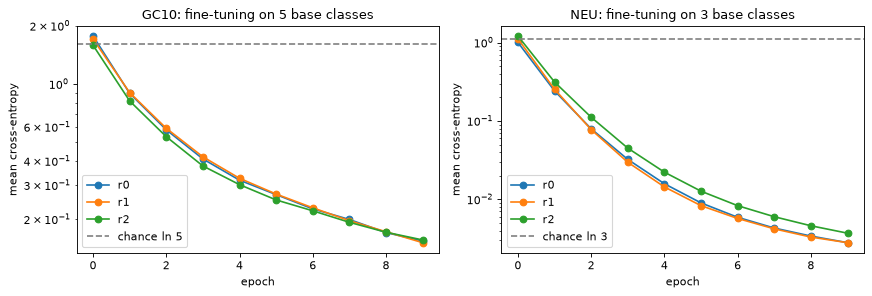

In [7]:
# cell 6: mean cross-entropy per epoch of the 6 ft runs (console.log), table and plot (log scale, chance level ln K)
import matplotlib.pyplot as plt
curves = {}
for d in sorted(Path("runs").glob("*__*_ft_cls*first_img80pct_r[0-2]")):
    curves[d.name.split("__")[1]] = [float(x) for x in re.findall(r"Epoch \d+: mean CE = ([\d.]+)", (d / "console.log").read_text(errors="replace"))]
print(pd.DataFrame(curves).rename_axis("epoch").round(4).T.to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), dpi=80)
for ax, (ds, k) in zip(axes, (("gc10", 5), ("neu", 3))):
    for tag, ce in curves.items():
        if tag.startswith(ds):
            ax.plot(range(len(ce)), ce, marker="o", label=tag.split("_")[-1])
    ax.axhline(np.log(k), color="gray", linestyle="--", label=f"chance ln {k}")
    ax.set(yscale="log", xlabel="epoch", ylabel="mean cross-entropy", title=f"{ds.upper()}: fine-tuning on {k} base classes")
    ax.legend()
plt.tight_layout()
plt.show()

- **Kết quả**:
  - GC10: CE ở epoch 0 là 1.59–1.77, quanh mức ngẫu nhiên ln 5 ≈ 1.61. Đến epoch 9 còn 0.151–0.156. Epoch cuối vẫn giảm khoảng 10% (r0: 0.1707 → 0.1544). Ba seed gần như trùng nhau từ epoch 2.
  - NEU: CE từ 1.00–1.21 (ln 3 ≈ 1.10) xuống 0.0028–0.0037. Trên thang log, đường giảm gần thẳng, tức CE giảm theo cấp số nhân. r2 chậm hơn một chút.
- **Ý nghĩa**:
  - GC10 chưa hội tụ ở epoch 10: CE còn giảm đều, khớp với 2.3 (tham số chạm giới hạn số bước). NEU gần như thuộc lòng tập huấn luyện sau khoảng 3 epoch.
  - Đây là CE trên chính ảnh huấn luyện, có dropout của BOFT, tính trung bình trong epoch. Không có tập kiểm định (held-out), nên không biết thêm epoch sẽ làm đặc trưng tốt hơn hay chỉ khớp quá (overfit).
  - [SUY LUẬN] Số epoch là một siêu tham số chưa được kiểm trên GC10. Muốn trả lời cần run, nên để thành câu hỏi, không làm ở đây.

## Summary (EN)

1. **What was trained.** All 6 `ft` runs use AdamW (lr 1e-3), effective batch 128 (32 × 4), 10 epochs and cross-entropy only (λ = 0, D3): 60 optimizer steps on 764 GC10 images and 50 on 576 NEU images. All runs have 221,184 trainable backbone parameters, which is butterfly factor 1 (A5). BOFT wraps only the 24 `output.dense` modules (attention output and second MLP layer). `mlp.fc1` and `mlp.fc2` match no module in transformers 4.46.3. The pooler stays frozen at its random initialisation (§1.1–1.2).
2. **The mechanism, checked by hand.** Each wrapped layer uses W′ = diag(s) · W · Mᵀ, where M is block-diagonal with 4 × 4 Cayley rotations Q = (I − S)(I + S)⁻¹ and P = I. Rebuilt by hand, this reproduces peft's output to 9.5e-07 (§2.1). The rotations are small (median block angle 4.8–5.1°). Every layer's effective weight changes by 5.7–8.0% (§2.2).
3. **Seeds agree in size, not in direction.** The correlation of the learned rotation parameters across the three GC10 seeds is 0.24–0.46 in layer 0 and at most 0.14 in layers 7–11. The largest parameter (0.045–0.061) sits at the 0.06 budget of 60 steps × lr (§2.3). [inference] Fine-tuning is step-limited, and the deep-layer changes are seed-specific, a candidate cause of the FT-seed instability of novel-class discovery (E09.05).
4. **Not converged on GC10.** Training cross-entropy falls from about ln 5 to 0.151–0.156 and is still dropping about 10% per epoch at epoch 9. NEU reaches 0.0028–0.0037 (§3.1). [inference] The number of epochs is untested for GC10; there is no held-out loss.